# 04 · Ajuste: elegir y congelar la configuración

**Qué hace:** entrena las 32 configuraciones de la rejilla con objetivos hasta 2014-09-12 y las compara en las 8 semanas de validación (2014-09-13 a 2014-11-07). Elige la de menor MAE en el escenario operativo y la congela en `configuracion/congelada.json`.

**Decisiones que aplica:** D-08 (pérdida del P50: `quantile` o `poisson`), D-11 (rejilla fija, sin detención temprana, `random_state = 2026`), D-10 (tramos), D-14 (MAE como métrica principal).

**Sin fuga:** `early_stopping=False` (la validación aleatoria de HistGradientBoosting mezclaría el futuro con el pasado). El entrenamiento solo tiene objetivos ≤ 2014-09-12; la validación son cortes semanales posteriores. **La prueba (desde 2014-11-08) no se toca.**

**Criterio:** menor MAE con `h` de 2 a 8 (escenario operativo: el núcleo decide con los datos de ayer, CONTRATO 2.3). `h = 1` se informa aparte. Empates: gana la combinación que aparece primero en la rejilla.

**Necesita:** `salidas/stuttgart/` del cuaderno 01. **Deja:** `configuracion/congelada.json` y `resultados/ajuste/`. **Esa configuración se sube al repositorio con un commit antes de ejecutar el 05.**

In [1]:
# Parámetros
import json, hashlib, itertools, time
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "cuadernos" else Path.cwd()
CONF = RAIZ / "configuracion"
SALIDA = RAIZ / "salidas" / "stuttgart"
RESULTADOS = RAIZ / "resultados" / "ajuste"
RESULTADOS.mkdir(parents=True, exist_ok=True)

rejilla = json.loads((CONF / "rejilla.json").read_text(encoding="utf-8"))
tramos = json.loads((CONF / "tramos_stuttgart.json").read_text(encoding="utf-8"))
FIN_ENTRENAMIENTO = "2014-09-12"            # último objetivo del entrenamiento
VAL_INICIO, VAL_FIN = tramos["validacion"]  # 2014-09-13 a 2014-11-07
H_OP = tuple(tramos["horizontes_operativos"])
SEMILLA = rejilla["random_state"]
print(VAL_INICIO, VAL_FIN, H_OP, SEMILLA)

2014-09-13 2014-11-07 (2, 8) 2026


In [2]:
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
from sklearn.ensemble import HistGradientBoostingRegressor
from rc_pronostico.variables import (LISTA_VARIABLES, CATEGORICAS, VERSION_VARIABLES,
                                     codigos_producto, filas_entrenamiento)
from rc_pronostico.baselines import baselines

historial = pd.read_parquet(SALIDA / "historial.parquet")
calendario = json.loads((SALIDA / "calendario.json").read_text(encoding="utf-8"))
codigos = codigos_producto(historial)
assert tramos["entrenamiento_inicial_hasta"] == VAL_FIN

## 1. Entrenamiento y validación
Se calcula una sola vez la tabla de filas con objetivos hasta 2014-11-07. De ahí:
- **Entrenamiento:** filas con objetivo ≤ 2014-09-12.
- **Validación:** cortes **semanales** `d = 2014-09-12, 09-19, …` (el mismo día de la semana), con sus objetivos hasta 2014-11-07. Los rezagos de la validación usan ventas reales hasta `d`, como en producción.

In [3]:
todas = filas_entrenamiento(historial, calendario, VAL_FIN, codigos)
entrenamiento = todas[todas.fecha_objetivo <= FIN_ENTRENAMIENTO].reset_index(drop=True)

cortes = pd.date_range(FIN_ENTRENAMIENTO, VAL_FIN, freq="7D")
validacion = todas[todas.fecha_corte.isin(cortes) & (todas.fecha_objetivo > FIN_ENTRENAMIENTO)].reset_index(drop=True)

# El entrenamiento es idéntico al que se obtendría cortando el historial en 2014-09-12 (sin fuga)
directo = filas_entrenamiento(historial, calendario, FIN_ENTRENAMIENTO, codigos)
pd.testing.assert_frame_equal(entrenamiento, directo, check_dtype=False)

print(f"entrenamiento: {len(entrenamiento)} filas, objetivos {entrenamiento.fecha_objetivo.min().date()} a {entrenamiento.fecha_objetivo.max().date()}")
print(f"validación: {len(validacion)} filas, {len(cortes) - 1} cortes semanales, objetivos {validacion.fecha_objetivo.min().date()} a {validacion.fecha_objetivo.max().date()}")

entrenamiento: 17248 filas, objetivos 2013-11-08 a 2014-09-12
validación: 441 filas, 8 cortes semanales, objetivos 2014-09-13 a 2014-11-07


## 2. Baselines en el mismo tramo (referencia)

In [4]:
bl = baselines(historial, calendario, validacion)
op = validacion.h.between(*H_OP).to_numpy()
ref = pd.DataFrame({
    "MAE h=2..8": [(validacion.y - bl.ingenuo)[op].abs().mean(), (validacion.y - bl.media_mismo_dia)[op].abs().mean()],
    "MAE h=1": [(validacion.y - bl.ingenuo)[~op].abs().mean(), (validacion.y - bl.media_mismo_dia)[~op].abs().mean()]},
    index=["ingenuo estacional", "media del mismo día (4)"]).round(4)
ref

,MAE h=2..8,MAE h=1
ingenuo estacional,5.2182,6.6964
media del mismo día (4),4.1370,4.5268


## 3. Las 32 combinaciones
Cada una es un `HistGradientBoostingRegressor` con `producto` como categórica, sin detención temprana. Se mide el MAE de la mediana en el escenario operativo.

In [5]:
def ajustar(p, perdida, X, y):
    kw = dict(loss="quantile", quantile=0.5) if perdida == "quantile" else dict(loss="poisson")
    m = HistGradientBoostingRegressor(
        **kw, learning_rate=p["learning_rate"], max_iter=p["max_iter"],
        max_leaf_nodes=p["max_leaf_nodes"], min_samples_leaf=p["min_samples_leaf"],
        categorical_features=CATEGORICAS, early_stopping=False, random_state=SEMILLA)
    return m.fit(X, y)

claves = ["learning_rate", "max_iter", "max_leaf_nodes", "min_samples_leaf"]
combos = [dict(zip(claves, v)) for v in itertools.product(*(rejilla[k] for k in claves))]
assert len(combos) * len(rejilla["perdida_p50"]) == 32

X_ent, y_ent = entrenamiento[LISTA_VARIABLES], entrenamiento.y
X_val = validacion[LISTA_VARIABLES]
filas = []
t0 = time.time()
for perdida in rejilla["perdida_p50"]:
    for p in combos:
        m = ajustar(p, perdida, X_ent, y_ent)
        pred = np.clip(m.predict(X_val), 0, None)
        err = (validacion.y - pred)
        filas.append({"perdida_p50": perdida, **p,
                      "MAE_operativo": err[op].abs().mean(), "MAE_h1": err[~op].abs().mean(),
                      "sesgo_operativo": (-err[op]).mean()})
print(f"{len(filas)} combinaciones en {time.time() - t0:.0f} s")
ajuste = pd.DataFrame(filas)
ajuste.insert(0, "n", range(1, len(ajuste) + 1))
ajuste.round(4)

32 combinaciones en 25 s


,n,perdida_p50,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE_operativo,MAE_h1,sesgo_operativo
0,1,quantile,0.05,200,15,20,4.3189,5.6087,-0.0485
1,2,quantile,0.05,200,15,50,4.2393,5.0624,0.0869
2,3,quantile,0.05,200,31,20,4.4200,5.3692,0.2568
3,4,quantile,0.05,200,31,50,4.4041,5.0389,0.3389
4,5,quantile,0.05,500,15,20,4.4463,5.4503,0.1499
5,6,quantile,0.05,500,15,50,4.3805,5.0257,0.2009
6,7,quantile,0.05,500,31,20,4.4983,5.1636,0.3578
7,8,quantile,0.05,500,31,50,4.5689,4.9404,0.5528
8,9,quantile,0.10,200,15,20,4.3552,5.3903,0.1465
9,10,quantile,0.10,200,15,50,4.2930,5.0196,0.1862


## 4. Elección
Menor MAE operativo (`h` de 2 a 8). En un empate exacto, la primera de la rejilla.

In [6]:
mejor = ajuste.loc[ajuste.MAE_operativo.idxmin()]
ranking = ajuste.sort_values(["MAE_operativo", "n"]).reset_index(drop=True)
ranking.index += 1
print("Elegida: combinación", int(mejor.n))
print(mejor.to_dict())
ranking.head(10).round(4)

Elegida: combinación 2
{'n': 2, 'perdida_p50': 'quantile', 'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 50, 'MAE_operativo': 4.239349064841288, 'MAE_h1': 5.062430241905015, 'sesgo_operativo': 0.08685474007462768}


,n,perdida_p50,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,MAE_operativo,MAE_h1,sesgo_operativo
1,2,quantile,0.05,200,15,50,4.2393,5.0624,0.0869
2,10,quantile,0.10,200,15,50,4.2930,5.0196,0.1862
3,1,quantile,0.05,200,15,20,4.3189,5.6087,-0.0485
4,9,quantile,0.10,200,15,20,4.3552,5.3903,0.1465
5,6,quantile,0.05,500,15,50,4.3805,5.0257,0.2009
6,17,poisson,0.05,200,15,20,4.4000,5.5093,0.5856
7,4,quantile,0.05,200,31,50,4.4041,5.0389,0.3389
8,3,quantile,0.05,200,31,20,4.4200,5.3692,0.2568
9,14,quantile,0.10,500,15,50,4.4232,4.8136,0.3544
10,18,poisson,0.05,200,15,50,4.4282,5.3817,0.5997


In [7]:
# Por pérdida: la mejor combinación de cada una
ajuste.groupby("perdida_p50").MAE_operativo.agg(["min", "mean", "max"]).round(4)

,min,mean,max
perdida_p50,,,
poisson,4.4000,4.6542,4.8710
quantile,4.2393,4.4401,4.6787


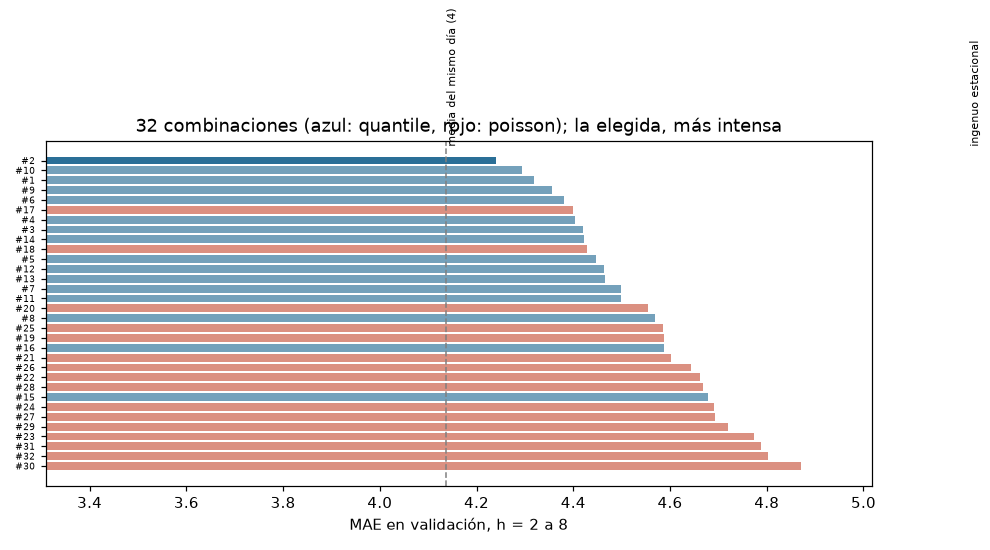

In [8]:
ajuste.round(6).to_csv(RESULTADOS / "ajuste_32_combinaciones.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5))
orden = ajuste.sort_values("MAE_operativo").reset_index(drop=True)
colores = {"quantile": "#2a6f97", "poisson": "#c8553d"}
for i, r in orden.iterrows():
    ax.barh(i, r.MAE_operativo, color=colores[r.perdida_p50], alpha=1 if r.n == mejor.n else .65)
ax.set_yticks(range(len(orden))); ax.set_yticklabels([f"#{int(n)}" for n in orden.n], fontsize=6)
ax.invert_yaxis()
for nombre, v in zip(ref.index, ref["MAE h=2..8"]):
    ax.axvline(v, ls="--", lw=1, color="grey"); ax.text(v, -1, " " + nombre, fontsize=7, rotation=90, va="bottom")
ax.set_xlabel("MAE en validación, h = 2 a 8")
ax.set_xlim(ref["MAE h=2..8"].min() * .8, orden.MAE_operativo.max() * 1.03)
ax.set_title("32 combinaciones (azul: quantile, rojo: poisson); la elegida, más intensa")
fig.tight_layout(); fig.savefig(RESULTADOS / "ajuste_32_combinaciones.png", dpi=110); plt.close(fig)
display(Image(RESULTADOS / "ajuste_32_combinaciones.png"))

## 5. Cómo se porta la elegida
Con la configuración elegida se mira el detalle de la validación, solo para informar (no cambia la elección): por `h`, frente a los baselines, y el P90 con los mismos hiperparámetros y `loss="quantile", quantile=0.9`.

In [9]:
p = {k: (int(mejor[k]) if k != "learning_rate" else float(mejor[k])) for k in claves}
m50 = ajustar(p, mejor.perdida_p50, X_ent, y_ent)
m90 = HistGradientBoostingRegressor(loss="quantile", quantile=0.9, **p, categorical_features=CATEGORICAS,
                                    early_stopping=False, random_state=SEMILLA).fit(X_ent, y_ent)
p50 = np.clip(m50.predict(X_val), 0, None)
p90 = np.maximum(np.clip(m90.predict(X_val), 0, None), p50)   # garantía 4.2: p90 >= p50

d = validacion.assign(p50=p50, p90=p90, ingenuo=bl.ingenuo, media4=bl.media_mismo_dia, p90_bl=bl.p90_mismo_dia)
por_h = d.groupby("h").apply(lambda g: pd.Series({
    "MAE_modelo": (g.y - g.p50).abs().mean(), "MAE_ingenuo": (g.y - g.ingenuo).abs().mean(),
    "MAE_media4": (g.y - g.media4).abs().mean(),
    "cobertura_P90_modelo": (g.y <= g.p90).mean(), "cobertura_P90_baseline": (g.y <= g.p90_bl).mean()}), include_groups=False)
por_h.round(3)

,MAE_modelo,MAE_ingenuo,MAE_media4,cobertura_P90_modelo,cobertura_P90_baseline
h,,,,,
1,5.062,6.696,4.527,0.804,0.857
2,3.074,4.036,3.205,0.964,0.839
3,4.737,6.429,4.612,0.821,0.821
4,3.693,4.571,4.286,0.946,0.893
5,4.423,5.161,4.174,0.946,1.000
6,3.673,4.696,3.871,0.929,0.821
7,4.277,4.946,3.924,0.911,0.768
8,6.021,6.898,4.995,0.755,0.857


In [10]:
def pinball(y, q, tau): return np.maximum(tau * (y - q), (tau - 1) * (y - q)).mean()
resumen = pd.Series({
    "MAE modelo (h=2..8)": (d.y - d.p50)[op].abs().mean(),
    "MAE ingenuo (h=2..8)": (d.y - d.ingenuo)[op].abs().mean(),
    "MAE media4 (h=2..8)": (d.y - d.media4)[op].abs().mean(),
    "pinball 0,9 modelo": pinball(d.y, d.p90, .9), "pinball 0,9 baseline": pinball(d.y, d.p90_bl, .9),
    "cobertura P90 modelo": (d.y <= d.p90).mean(), "cobertura P90 baseline": (d.y <= d.p90_bl).mean()})
resumen.round(4)

MAE modelo (h=2..8)       4.2393
MAE ingenuo (h=2..8)      5.2182
MAE media4 (h=2..8)       4.1370
pinball 0,9 modelo        0.9752
pinball 0,9 baseline      1.0315
cobertura P90 modelo      0.8866
cobertura P90 baseline    0.8571
dtype: float64

## 6. Congelar
Se escribe la configuración elegida. Sin marca de tiempo, para que dos ejecuciones den el mismo archivo.

In [11]:
csv_sha = (RAIZ / "dataset" / "stuttgart" / "FICHA.md").read_text(encoding="utf-8").split("| SHA-256 | `")[1].split("`")[0]
congelada = {
    "descripcion": "Configuracion elegida en la validacion de Stuttgart (D-11). No se modifica despues de ver la prueba.",
    "p50": {"loss": mejor.perdida_p50, **({"quantile": 0.5} if mejor.perdida_p50 == "quantile" else {})},
    "p90": {"loss": "quantile", "quantile": 0.9},
    "hiperparametros": p,
    "categorical_features": CATEGORICAS,
    "early_stopping": False,
    "random_state": SEMILLA,
    "version_variables": VERSION_VARIABLES,
    "variables": LISTA_VARIABLES,
    "criterio": f"menor MAE con h de {H_OP[0]} a {H_OP[1]} en la validacion {VAL_INICIO} a {VAL_FIN}",
    "mae_validacion_operativo": round(float(mejor.MAE_operativo), 6),
    "combinacion": int(mejor.n),
    "datos_sha256": csv_sha,
    "filas_entrenamiento": int(len(entrenamiento)),
}
(CONF / "congelada.json").write_text(json.dumps(congelada, indent=1, ensure_ascii=False) + "\n", encoding="utf-8")
congelada

{'descripcion': 'Configuracion elegida en la validacion de Stuttgart (D-11). No se modifica despues de ver la prueba.',
 'p50': {'loss': 'quantile', 'quantile': 0.5},
 'p90': {'loss': 'quantile', 'quantile': 0.9},
 'hiperparametros': {'learning_rate': 0.05,
  'max_iter': 200,
  'max_leaf_nodes': 15,
  'min_samples_leaf': 50},
 'categorical_features': ['producto'],
 'early_stopping': False,
 'random_state': 2026,
 'version_variables': '1',
 'variables': ['dia_semana',
  'dia_mes',
  'mes',
  'es_feriado',
  'vispera_feriado',
  'pos_feriado',
  'h',
  'producto',
  'lag0',
  'lag1',
  'lag2',
  'lag3',
  'lag4',
  'lag5',
  'lag6',
  'media_7',
  'media_28',
  'desv_28',
  'ultimo_mismo_dia',
  'media_mismo_dia_4',
  'tendencia'],
 'criterio': 'menor MAE con h de 2 a 8 en la validacion 2014-09-13 a 2014-11-07',
 'mae_validacion_operativo': 4.239349,
 'combinacion': 2,
 'datos_sha256': 'eb7d66f029043e000016015666410ab0b6921d268b20c290a01b1c8949673e8b',
 'filas_entrenamiento': 17248}

## Verificaciones

In [12]:
assert len(ajuste) == 32 and ajuste.n.is_unique
assert entrenamiento.fecha_objetivo.max() <= pd.Timestamp(FIN_ENTRENAMIENTO)
assert validacion.fecha_objetivo.min() > pd.Timestamp(FIN_ENTRENAMIENTO)
assert validacion.fecha_objetivo.max() <= pd.Timestamp(VAL_FIN) < pd.Timestamp(tramos["prueba"][0]), "la validacion no puede tocar la prueba"
assert set(validacion.fecha_corte.unique()) <= set(cortes)
assert (validacion.fecha_corte >= pd.Timestamp(FIN_ENTRENAMIENTO)).all()
assert congelada["early_stopping"] is False and congelada["random_state"] == 2026
assert ajuste.MAE_operativo.notna().all() and (p50 >= 0).all() and (p90 >= p50).all()
assert congelada["variables"] == LISTA_VARIABLES
assert json.loads((CONF / "congelada.json").read_text(encoding="utf-8"))["combinacion"] == int(mejor.n)
print("OK · configuración elegida y congelada:", congelada["p50"], congelada["hiperparametros"])

OK · configuración elegida y congelada: {'loss': 'quantile', 'quantile': 0.5} {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 15, 'min_samples_leaf': 50}
